# Segmentation quality

In [1]:
import os, sys, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import torch
import torch.nn.functional as F
import torchxrayvision as xrv

ROOT = "/zhome/d0/a/221493/thesis/final_experiment"
sys.path.insert(0, os.path.join(ROOT, "code"))
import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

DATA_ROOT = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
SPLIT_CSV = os.path.join(ROOT, "C2_dataset.csv")
N, SEED = 8, 0

# Every figure is also written to FIG_DIR as PDF (vector, for \includegraphics) and PNG.
SAVE_FIGS   = True
FIG_DIR     = os.path.join(ROOT, "figures", "segmentation")
FIG_FORMATS = ("pdf", "png")

def fig_path(name, ext):
    return os.path.join(FIG_DIR, f"segmentation_{name}.{ext}")

def save(fig, name):
    """Write `fig` as FIG_DIR/segmentation_<name>.{pdf,png}."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in FIG_FORMATS:
            fig.savefig(fig_path(name, ext))

def save_text(name, text):
    """Write a figure's caption / details beside it as <name>.txt."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        with open(fig_path(name, "txt"), "w", encoding="utf-8") as f:
            f.write(text.rstrip() + "\n")

/work3/s251710/venv_flexray/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Draw a random subset and let CheX_Dataset do the loading (it drops the few non-AP/PA rows)
split = pd.read_csv(SPLIT_CSV)
split = split[split["AP/PA"].isin(["AP", "PA"])].sample(N, random_state=SEED)
tmp_csv = os.path.join(os.environ.get("TMPDIR", "/tmp"), "seg_viz_train.csv")  # name must contain 'train'
split.to_csv(tmp_csv, index=False)

ds = xrv.datasets.CheX_Dataset(imgpath=os.path.join(DATA_ROOT, "CheXpert-v1.0-small"), csvpath=tmp_csv,
                               views=["PA", "AP"], transform=xrv.datasets.XRayResizer(224), unique_patients=False)
imgs = torch.stack([torch.from_numpy(ds[i]["img"]) for i in range(len(ds))])   # (N,1,224,224), [-1024,1024]

seg = xrv.baseline_models.chestx_det.PSPNet().eval()
with torch.no_grad():
    logits = seg(imgs)
masks = (torch.sigmoid(F.interpolate(logits, size=imgs.shape[-2:], mode="bilinear", align_corners=False)) >= 0.5).numpy()
TARGETS = seg.targets
print(imgs.shape, masks.shape, TARGETS)

torch.Size([8, 1, 224, 224]) (8, 14, 224, 224) ['Left Clavicle', 'Right Clavicle', 'Left Scapula', 'Right Scapula', 'Left Lung', 'Right Lung', 'Left Hilus Pulmonis', 'Right Hilus Pulmonis', 'Heart', 'Aorta', 'Facies Diaphragmatica', 'Mediastinum', 'Weasand', 'Spine']


In [3]:
# Share of images where each structure came back empty (these become NaN attributes downstream)
empty = pd.Series(masks.reshape(len(masks), len(TARGETS), -1).sum(-1).__eq__(0).mean(0), index=TARGETS)
empty.rename("empty fraction").to_frame()

,empty fraction
Left Clavicle,0.250
Right Clavicle,0.000
Left Scapula,0.000
Right Scapula,0.000
Left Lung,0.000
Right Lung,0.000
Left Hilus Pulmonis,0.250
Right Hilus Pulmonis,0.000
Heart,0.000
Aorta,0.375


In [23]:
# ── drawing helpers ──────────────────────────────────────────────────────────
# Colour = the organ, the same palette as the dumbbells and case cards in attribute_explainability.
# Single-mask panels share one highlight colour, so no hue is spent on what is only "the mask".
HILITE = "#4F81BD"
OUTLINE_LW = 1.4          # pt; outline thickness of every mask
FILL_ALPHA = 0.35         # inside of a single mask
FILL_ALPHA_MULTI = 0.15   # inside of each mask when several organs overlap on one image
ORGAN = {"Lungs": "#4F81BD", "Heart": "#C0504D", "Mediastinum": "#F79646",
         "Diaphragm": "#4BACC6", "Spine": "#9BBB59"}
ORGAN_OF = {"Left Lung": "Lungs", "Right Lung": "Lungs", "Heart": "Heart",
            "Mediastinum": "Mediastinum", "Facies Diaphragmatica": "Diaphragm", "Spine": "Spine"}


def draw_mask(ax, m, color=HILITE, fill=FILL_ALPHA, lw=OUTLINE_LW):
    """One mask: translucent fill inside, solid outline on the edge."""
    if not m.any():
        return
    rgba = np.zeros((*m.shape, 4))
    rgba[m > 0] = to_rgba(color, fill)
    ax.imshow(rgba)
    ax.contour(m, levels=[0.5], colors=[color], linewidths=lw)


def show_mask(ax, img, m, color=HILITE, fill=FILL_ALPHA, lw=OUTLINE_LW):
    """X-ray with one mask on top."""
    ax.imshow(img, cmap="gray")
    draw_mask(ax, m, color, fill, lw)
    ax.axis("off")


def small_title(ax, text, width=16):
    """Tiny wrapped name above a thumbnail; the bold 7.5 pt default would not fit 25 mm squares."""
    ax.set_title("\n".join(textwrap.wrap(text.replace("_", " "), width)), loc="left", pad=2,
                 fontsize=FS["small"], fontweight="normal")


def row_label(ax, text):
    ax.text(-0.06, 0.5, text, transform=ax.transAxes, rotation=90, va="center", ha="right",
            fontsize=FS["small"])


def grid(nrows, ncols, side_mm, extra_mm, gap_mm=1.2):
    """nrows x ncols of equal squares across the full text width."""
    fig, axes = plt.subplots(nrows, ncols, squeeze=False, layout="constrained",
                             figsize=(FULL, (nrows * (side_mm + gap_mm) + extra_mm) * MM))
    fig.get_layout_engine().set(w_pad=0.5 * MM, h_pad=0.5 * MM, wspace=0.01, hspace=0.01)
    return fig, axes


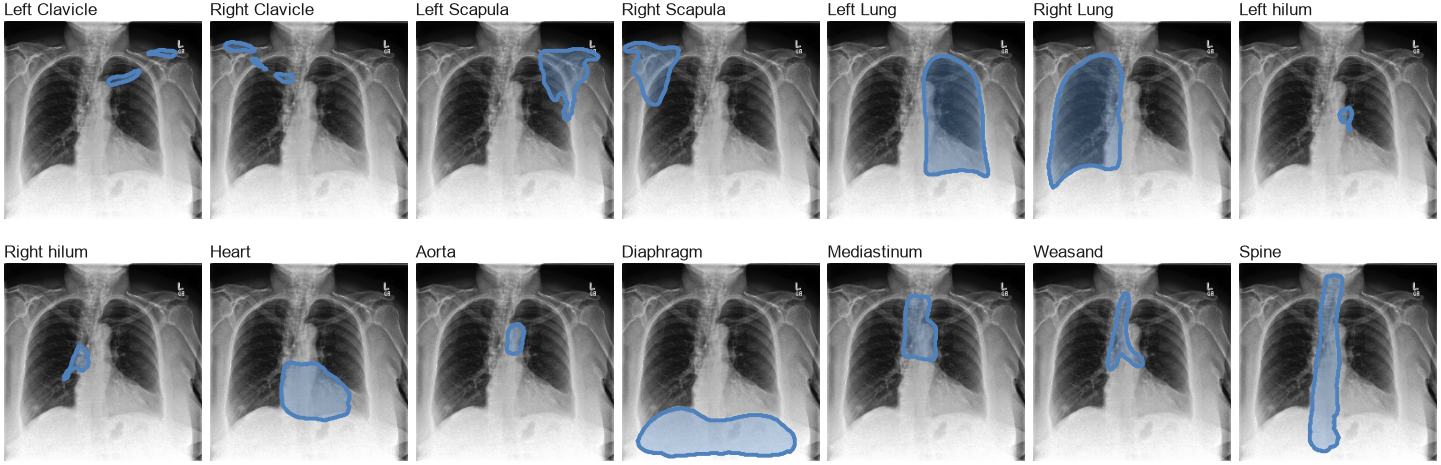

In [24]:
# One image, all 14 structures
SHORT = {"Left Hilus Pulmonis": "Left hilum", "Right Hilus Pulmonis": "Right hilum",
         "Facies Diaphragmatica": "Diaphragm"}

i = 0
fig, axes = grid(2, 7, side_mm=(FULL / MM - 4) / 7, extra_mm=8)
for k, ax in enumerate(axes.flat):
    show_mask(ax, imgs[i, 0], masks[i, k])
    small_title(ax, SHORT.get(TARGETS[k], TARGETS[k]), width=40)    # width 40: never wrap
save(fig, "all_structures")
save_text("all_structures", f"PSPNet (chestx_det) masks for one random C2_dataset image, thresholded "
          f"at 0.5, shaded with an outline. Panel titles are shortened: " +
          ", ".join(f"{s} = {f}" for f, s in SHORT.items()) +
          f". Image: {split.iloc[i]['Path']}.")
plt.show()

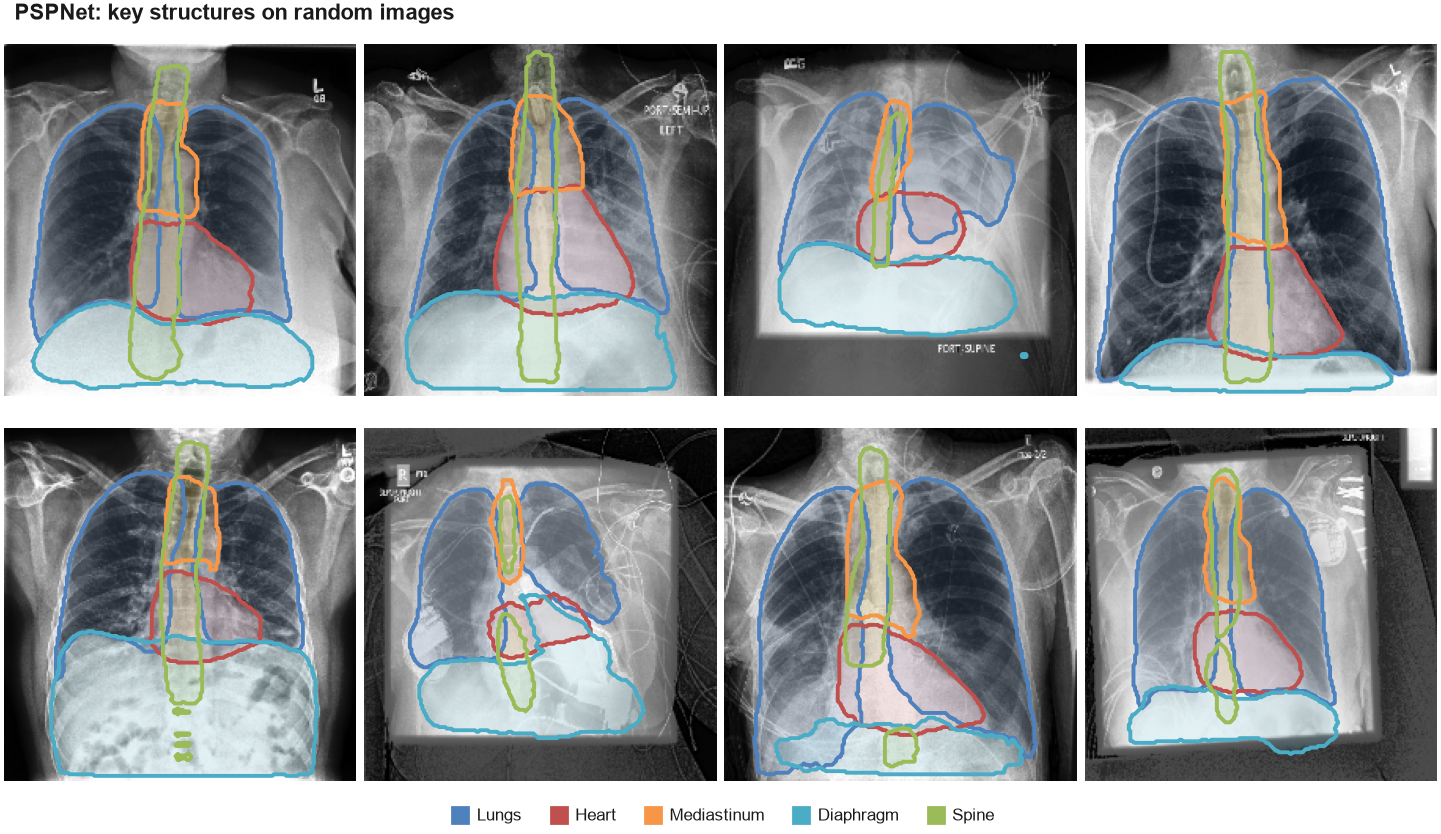

In [25]:
# Several images, key structures shaded and outlined, coloured by organ
SHOW = ["Left Lung", "Right Lung", "Heart", "Mediastinum", "Facies Diaphragmatica", "Spine"]

ncols = N // 2
fig, axes = grid(2, ncols, side_mm=(FULL / MM - 4) / ncols, extra_mm=14)
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i, 0], cmap="gray")
    for name in SHOW:
        draw_mask(ax, masks[i, TARGETS.index(name)], ORGAN[ORGAN_OF[name]], fill=FILL_ALPHA_MULTI)
    ax.axis("off")
fig.suptitle("PSPNet: key structures on random images", x=0.01, ha="left")
fig.legend(handles=[patch_handle(c, n) for n, c in ORGAN.items()], loc="outside lower center",
           ncol=len(ORGAN), handletextpad=0.2, columnspacing=1.4)
save(fig, "examples")
save_text("examples", f"PSPNet masks on {N} random C2_dataset images (seed {SEED}), 0.5 threshold. "
          f"Colour is the organ; left and right lung share one. Images: " + "; ".join(split["Path"]))
plt.show()
